1. Use default sample values
2. Enter custom values


Select an option (1 or 2):  1



Using default sample values...

          TASK SCHEDULING MODULE             

 SELECTED NON-OVERLAPPING ACTIVITIES:
Activity Name   | Start Time   | Finish Time 
-----------------------------------------------
Act_1           | 1            | 4           
Act_4           | 5            | 7           
Act_8           | 8            | 11          
Act_11          | 12           | 14          

 SCHEDULING METRICS SUMMARY:
Total Activities Considered : 11
Maximum Activities Solved   : 4
Names of Solved Activities  : Act_1, Act_4, Act_8, Act_11

 DYNAMIC PERFORMANCE METRICS (CURRENT RUN):
Measured Execution Time     : 29.20 microseconds
Tracked Object Memory      : 672 bytes

      GREEDY ALGORITHMS COMPLEXITY TABLE     
Algorithm Name               | Time Complexity | Space Complexity
-----------------------------------------------------------------
Activity Selection (Current) | O(N log N)      | O(N)
Fractional Knapsack          | O(N log N)      | O(N)
Job Sequencing with Deadlines |

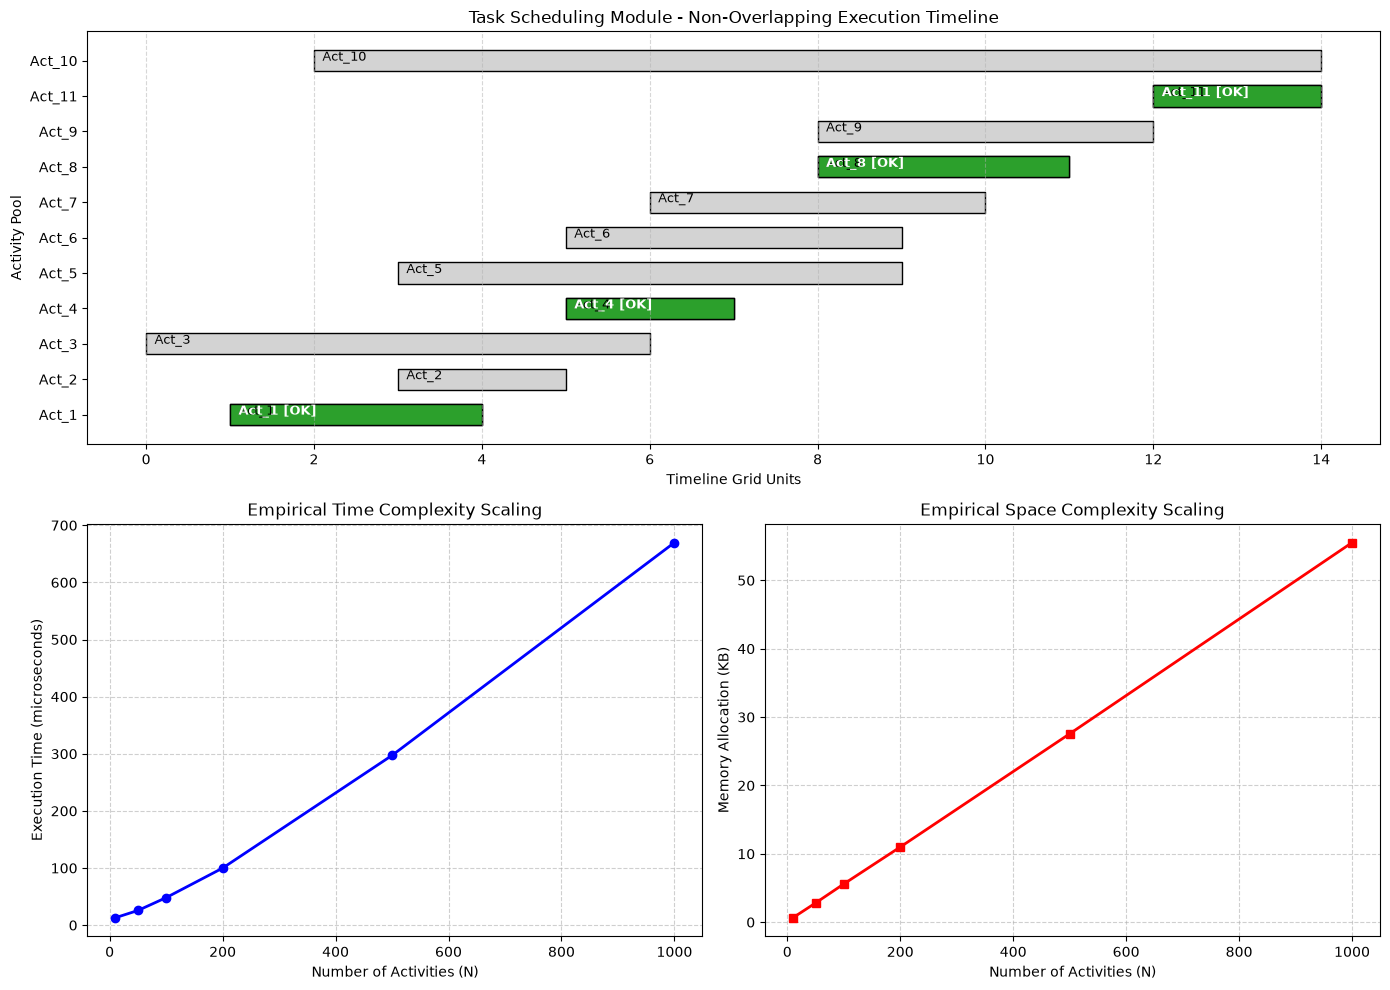

In [2]:
import time
import sys
import random
import matplotlib.pyplot as plt

class Activity:
    def __init__(self, name, start, finish):
        self.name = name
        self.start = start
        self.finish = finish

def activity_selection(activities):
    selected_activities = []
    if not activities:
        return selected_activities
        
    activities.sort(key=lambda x: x.finish)
    
    last_finish_time = 0
    for activity in activities:
        if activity.start >= last_finish_time:
            selected_activities.append(activity)
            last_finish_time = activity.finish
            
    return selected_activities

def run_performance_benchmark():
    sizes = [10, 50, 100, 200, 500, 1000]
    time_taken = []
    memory_used = []
    
    for size in sizes:
        test_pool = []
        for i in range(size):
            start = random.randint(0, 1000)
            finish = start + random.randint(1, 50)
            test_pool.append(Activity(f"Act_{i}", start, finish))
            
        t_start = time.perf_counter_ns()
        _ = activity_selection(test_pool)
        t_end = time.perf_counter_ns()
        
        mem = sys.getsizeof(test_pool) + sum(sys.getsizeof(a) for a in test_pool)
        
        time_taken.append((t_end - t_start) / 1000)
        memory_used.append(mem / 1024)
        
    return sizes, time_taken, memory_used

if __name__ == "__main__":
    print("1. Use default sample values")
    print("2. Enter custom values")
    choice = input("Select an option (1 or 2): ").strip()
    
    if choice == "2":
        num_activities = int(input("Enter the number of activities: "))
        activities_pool = []
        for i in range(num_activities):
            print(f"\n--- Activity {i+1} ---")
            name = input("Enter activity name: ")
            start = int(input("Enter start time: "))
            finish = int(input("Enter finish time: "))
            activities_pool.append(Activity(name, start, finish))
    else:
        print("\nUsing default sample values...")
        activities_pool = [
            Activity("Act_3", start=0, finish=6),
            Activity("Act_1", start=1, finish=4),
            Activity("Act_5", start=3, finish=9),
            Activity("Act_2", start=3, finish=5),
            Activity("Act_4", start=5, finish=7),
            Activity("Act_6", start=5, finish=9),
            Activity("Act_8", start=8, finish=11),
            Activity("Act_7", start=6, finish=10),
            Activity("Act_9", start=8, finish=12),
            Activity("Act_11", start=12, finish=14),
            Activity("Act_10", start=2, finish=14)
        ]
        
    start_time = time.perf_counter_ns()
    selected = activity_selection(activities_pool)
    end_time = time.perf_counter_ns()
    
    execution_time_us = (end_time - start_time) / 1000
    memory_used_bytes = sys.getsizeof(activities_pool) + sum(sys.getsizeof(act) for act in activities_pool)
    
    print("\n=============================================")
    print("          TASK SCHEDULING MODULE             ")
    print("=============================================")
    print("\n SELECTED NON-OVERLAPPING ACTIVITIES:")
    print(f"{'Activity Name':<15} | {'Start Time':<12} | {'Finish Time':<12}")
    print("-" * 47)
    for act in selected:
        print(f"{act.name:<15} | {act.start:<12} | {act.finish:<12}")
        
    print("\n SCHEDULING METRICS SUMMARY:")
    print(f"Total Activities Considered : {len(activities_pool)}")
    print(f"Maximum Activities Solved   : {len(selected)}")
    print("Names of Solved Activities  :", ", ".join([act.name for act in selected]))
    print("\n DYNAMIC PERFORMANCE METRICS (CURRENT RUN):")
    print(f"Measured Execution Time     : {execution_time_us:.2f} microseconds")
    print(f"Tracked Object Memory      : {memory_used_bytes} bytes")
    
    print("\n=============================================")
    print("      GREEDY ALGORITHMS COMPLEXITY TABLE     ")
    print("=============================================")
    print(f"{'Algorithm Name':<28} | {'Time Complexity':<15} | {'Space Complexity'}")
    print("-" * 65)
    print(f"{'Activity Selection (Current)':<28} | {'O(N log N)':<15} | {'O(N)'}")
    print(f"{'Fractional Knapsack':<28} | {'O(N log N)':<15} | {'O(N)'}")
    print(f"{'Job Sequencing with Deadlines':<28} | {'O(N^2)':<15} | {'O(N)'}")
    print(f"{'Huffman Coding':<28} | {'O(N log N)':<15} | {'O(N)'}")
    print(f"{'Dijkstra Shortest Path':<28} | {'O(E log V)':<15} | {'O(V)'}")
    print("=============================================")

    print("\nGenerating performance scaling graphs...")
    sizes, times, memories = run_performance_benchmark()

    fig = plt.figure(figsize=(14, 10))
    gs = fig.add_gridspec(2, 2)

    ax0 = fig.add_subplot(gs[0, :])
    for idx, act in enumerate(activities_pool):
        ax0.broken_barh([(act.start, act.finish - act.start)], (idx*10 + 2, 6), facecolors='lightgray', edgecolor='black')
        ax0.text(act.start + 0.1, idx*10 + 5, f"{act.name}", fontsize=9, color='black')
        if act in selected:
            ax0.broken_barh([(act.start, act.finish - act.start)], (idx*10 + 2, 6), facecolors='#2ca02c', edgecolor='black')
            ax0.text(act.start + 0.1, idx*10 + 5, f"{act.name} [OK]", fontsize=9, color='white', fontweight='bold')
    ax0.set_xlabel('Timeline Grid Units')
    ax0.set_ylabel('Activity Pool')
    ax0.set_yticks([i*10 + 5 for i in range(len(activities_pool))])
    ax0.set_yticklabels([act.name for act in activities_pool])
    ax0.grid(True, axis='x', linestyle='--', alpha=0.5)
    ax0.set_title('Task Scheduling Module - Non-Overlapping Execution Timeline')

    ax1 = fig.add_subplot(gs[1, 0])
    ax1.plot(sizes, times, marker='o', color='blue', linestyle='-', linewidth=2)
    ax1.set_title('Empirical Time Complexity Scaling')
    ax1.set_xlabel('Number of Activities (N)')
    ax1.set_ylabel('Execution Time (microseconds)')
    ax1.grid(True, linestyle='--', alpha=0.6)

    ax2 = fig.add_subplot(gs[1, 1])
    ax2.plot(sizes, memories, marker='s', color='red', linestyle='-', linewidth=2)
    ax2.set_title('Empirical Space Complexity Scaling')
    ax2.set_xlabel('Number of Activities (N)')
    ax2.set_ylabel('Memory Allocation (KB)')
    ax2.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()